# AI-Generated vs Real Video Detector (from scratch): local version

Runs on your own computer (Mac/Windows/Linux). **Run each cell in order with Shift+Enter.**
Uses your GPU if you have one (NVIDIA, or Apple Silicon), otherwise the CPU (slower).

In [ ]:
%pip install -q scikit-learn opencv-python-headless kagglehub

In [1]:
import torch, shutil
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE)
if shutil.which("ffmpeg"):
    print("ffmpeg found: audio will be used.")
else:
    print("ffmpeg NOT found: audio will be silent. Fix: run  conda install -c conda-forge ffmpeg  "
          "in Terminal, restart the kernel, or set USE_AUDIO = False in the next cell.")

PyTorch: 2.11.0 | device: mps
ffmpeg found: audio will be used.


## Step 1: Settings (smaller values so it runs faster on a laptop)

In [2]:
FRAMES, SIZE, BATCH, EPOCHS, LR = 8, 96, 8, 10, 3e-4
USE_AUDIO = True     # set to False if you have not installed ffmpeg
WORKERS = 0          # keep 0 on Mac/Windows notebooks
LOCAL_DATA = "./data"
CKPT_PATH = "./ai_video_best.pt"

## Step 2: Download the Kaggle dataset (real + AI videos)

In [3]:
%pip install -q kagglehub

import kagglehub, re, os, random
from pathlib import Path

MAX_PER_CLASS = 200   # videos used per class (smaller = faster). Use None for all.

path = Path(kagglehub.dataset_download("kanzeus/realai-video-dataset"))
print("Downloaded to:", path)

EXT = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
FAKE_WORDS = {"fake", "ai", "aigc", "generated", "synthetic", "deepfake", "deepfakes", "gen"}
REAL_WORDS = {"real", "authentic", "original", "genuine", "pristine"}


def guess_label(p):
    """Look at folder/file names, deepest first, to decide real vs fake."""
    for part in reversed(p.relative_to(path).parts):
        words = set(re.split(r"[^a-z]+", Path(part).stem.lower()))
        f, r = bool(words & FAKE_WORDS), bool(words & REAL_WORDS)
        if f and not r:
            return "fake"
        if r and not f:
            return "real"
    return None


def show_tree(root, depth=2):
    for dirpath, dirs, fs in os.walk(root):
        level = Path(dirpath).relative_to(root).parts
        if len(level) >= depth:
            dirs[:] = []
        n = sum(1 for f in fs if Path(f).suffix.lower() in EXT)
        print("  " * len(level) + Path(dirpath).name + f"/  ({n} videos here)")


videos = [p for p in path.rglob("*") if p.suffix.lower() in EXT]
groups = {"real": [], "fake": [], None: []}
for p in videos:
    groups[guess_label(p)].append(p)
print(f"Found {len(videos)} videos -> real: {len(groups['real'])}, "
      f"fake: {len(groups['fake'])}, unknown: {len(groups[None])}")

if not groups["real"] or not groups["fake"]:
    print("\nCould not tell real from fake automatically. Dataset layout:")
    show_tree(path)
    print("\nCopy this layout and send it to me so I can fix the labeling.")
else:
    random.seed(0)
    for label in ["real", "fake"]:
        os.makedirs(f"{LOCAL_DATA}/{label}", exist_ok=True)
        vids = groups[label]
        random.shuffle(vids)
        if MAX_PER_CLASS:
            vids = vids[:MAX_PER_CLASS]
        for i, p in enumerate(vids):
            dst = f"{LOCAL_DATA}/{label}/{i}_{p.name}"
            if not os.path.exists(dst):
                os.symlink(p, dst)
        print(f"'{label}': using {len(vids)} videos")

Note: you may need to restart the kernel to use updated packages.
Downloaded to: /Users/amishachhajed/.cache/kagglehub/datasets/kanzeus/realai-video-dataset/versions/1
Found 66 videos -> real: 33, fake: 33, unknown: 0
'real': using 33 videos
'fake': using 33 videos


## Step 3: Load the code (just run it)

In [4]:
import math, random, subprocess
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torchaudio
from torch.utils.data import DataLoader, Dataset

VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
SAMPLE_RATE, AUDIO_SECONDS, N_MELS = 16000, 4, 64
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

MEL = torchaudio.transforms.MelSpectrogram(SAMPLE_RATE, n_fft=1024, hop_length=256, n_mels=N_MELS)


def read_frames(path, num_frames, size, train):
    """Return float tensor (T, 6, H, W): RGB + frame-difference channels."""
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        raise ValueError(f"Unreadable video: {path}")
    seg = total / num_frames
    idxs = [min(int((i + (random.random() if train else 0.5)) * seg), total - 1)
            for i in range(num_frames)]
    frames, last = [], None
    for idx in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if not ok:
            frame = last if last is not None else np.zeros((size, size, 3), np.uint8)
        frame = cv2.resize(frame, (size, size), interpolation=cv2.INTER_AREA)
        last = frame
        frames.append(frame)
    cap.release()
    if train and random.random() < 0.5:
        frames = [f[:, ::-1] for f in frames]
    x = np.stack(frames).astype(np.float32) / 255.0
    x = x[..., ::-1]                                           # BGR -> RGB
    x = torch.from_numpy(np.ascontiguousarray(x)).permute(0, 3, 1, 2)
    diff = torch.zeros_like(x)
    diff[1:] = x[1:] - x[:-1]
    x = (x - 0.5) / 0.5
    return torch.cat([x, diff * 4.0], dim=1)


def read_audio(path):
    """Log-mel spectrogram (1, N_MELS, frames). Uses ffmpeg; zeros if no audio track."""
    n = SAMPLE_RATE * AUDIO_SECONDS
    wav = torch.zeros(n)
    try:
        raw = subprocess.run(
            ["ffmpeg", "-v", "quiet", "-i", str(path), "-vn", "-ac", "1",
             "-ar", str(SAMPLE_RATE), "-t", str(AUDIO_SECONDS), "-f", "s16le", "-"],
            capture_output=True, timeout=30).stdout
        if len(raw) > 2:
            w = torch.from_numpy(np.frombuffer(raw, np.int16).astype(np.float32) / 32768.0)
            wav[: min(n, len(w))] = w[:n]
    except Exception:
        pass
    return torch.log(MEL(wav) + 1e-6).unsqueeze(0)


class VideoDataset(Dataset):
    def __init__(self, items, num_frames, size, train, use_audio):
        self.items, self.num_frames, self.size = items, num_frames, size
        self.train, self.use_audio = train, use_audio

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, label = self.items[i]
        try:
            video = read_frames(path, self.num_frames, self.size, self.train)
        except Exception:                       # skip corrupt files gracefully
            video = torch.zeros(self.num_frames, 6, self.size, self.size)
        audio = read_audio(path) if self.use_audio else torch.zeros(1, N_MELS, AUDIO_SECONDS * SAMPLE_RATE // 256 + 1)
        return video, audio, torch.tensor(label, dtype=torch.float32)


def list_videos(root):
    items = []
    for label, name in [(0, "real"), (1, "fake")]:
        for p in sorted((Path(root) / name).rglob("*")):
            if p.suffix.lower() in VIDEO_EXT:
                items.append((p, label))
    return items

## Step 4: Build the model (just run it)

In [5]:
def conv_block(i, o, stride=1):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, stride, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))


class FrameEncoder(nn.Module):
    def __init__(self, in_ch=6, dim=256):
        super().__init__()
        self.net = nn.Sequential(
            conv_block(in_ch, 32, 2), conv_block(32, 64, 2),
            conv_block(64, 128, 2), conv_block(128, dim, 2),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())

    def forward(self, x):
        return self.net(x)


class AudioEncoder(nn.Module):
    def __init__(self, dim=256):
        super().__init__()
        self.net = nn.Sequential(
            conv_block(1, 16), nn.MaxPool2d(2), conv_block(16, 32), nn.MaxPool2d(2),
            conv_block(32, 64), nn.MaxPool2d(2), conv_block(64, dim),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())

    def forward(self, x):
        return self.net(x)


class AIVideoDetector(nn.Module):
    def __init__(self, num_frames=8, dim=256, use_audio=True):
        super().__init__()
        self.use_audio = use_audio
        self.frame_enc = FrameEncoder(6, dim)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, num_frames + 1, dim))
        layer = nn.TransformerEncoderLayer(dim, 4, dim * 2, dropout=0.1,
                                           batch_first=True, norm_first=True)
        self.temporal = nn.TransformerEncoder(layer, num_layers=2)
        self.audio_enc = AudioEncoder(dim) if use_audio else None
        fused = dim * 2 if use_audio else dim
        self.head = nn.Sequential(nn.Linear(fused, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 1))
        nn.init.trunc_normal_(self.pos, std=0.02)
        nn.init.trunc_normal_(self.cls, std=0.02)

    def forward(self, video, audio=None):
        B, T = video.shape[:2]
        f = self.frame_enc(video.flatten(0, 1).contiguous()).reshape(B, T, -1).contiguous()
        tokens = torch.cat([self.cls.expand(B, -1, -1), f], dim=1) + self.pos[:, : T + 1]
        v = self.temporal(tokens)[:, 0]
        if self.use_audio:
            v = torch.cat([v, self.audio_enc(audio)], dim=1)
        return self.head(v).squeeze(-1)


m = AIVideoDetector(FRAMES, use_audio=USE_AUDIO)
print(f"Parameters: {sum(p.numel() for p in m.parameters())/1e6:.2f}M")
del m

Parameters: 3.17M


/var/folders/nk/qlgnv72x3q5f5bclbnghpg580000gn/T/ipykernel_95876/1781843352.py:40: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=2)


## Step 5: Train (takes a while; wait for the Best val AUC line)

train: 57  val: 9


/var/folders/nk/qlgnv72x3q5f5bclbnghpg580000gn/T/ipykernel_95876/1781843352.py:40: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=2)


Training:   0%|          | 0/10 [00:00<?, ?epoch/s]

Epoch 1/10:   0%|          | 0/7 [00:00<?, ?batch/s]

epoch 001 loss 0.7202 val_acc 0.444 val_auc 0.450  <- saved


...

epoch 008 loss 0.5474 val_acc 0.444 val_auc 0.550


Epoch 9/10:   0%|          | 0/7 [00:00<?, ?batch/s]

epoch 009 loss 0.4382 val_acc 0.444 val_auc 0.400


Epoch 10/10:   0%|          | 0/7 [00:00<?, ?batch/s]

epoch 010 loss 0.5011 val_acc 0.444 val_auc 0.400
Best val AUC: 0.700  (checkpoint: ./ai_video_best.pt)


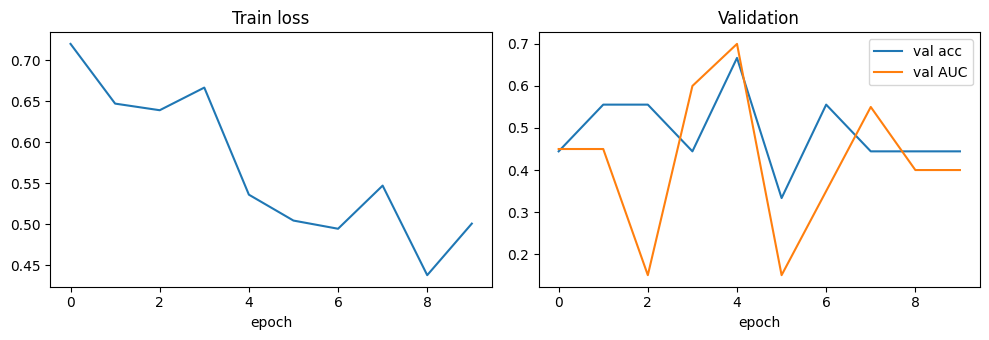

In [6]:
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

random.seed(0); torch.manual_seed(0)
items = list_videos(LOCAL_DATA)
assert len(items) >= 10, "Need videos in real/ and fake/ (more is much better)."
random.shuffle(items)
n_val = max(1, int(0.15 * len(items)))
val_items, train_items = items[:n_val], items[n_val:]
print(f"train: {len(train_items)}  val: {len(val_items)}")

mk = lambda it, tr: DataLoader(VideoDataset(it, FRAMES, SIZE, tr, USE_AUDIO),
                               batch_size=BATCH, shuffle=tr, num_workers=WORKERS,
                               drop_last=tr, pin_memory=(DEVICE == "cuda"), persistent_workers=WORKERS > 0)
train_dl, val_dl = mk(train_items, True), mk(val_items, False)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    probs, labels = [], []
    for v, a, y in loader:
        probs += torch.sigmoid(model(v.to(DEVICE), a.to(DEVICE))).cpu().tolist()
        labels += y.tolist()
    acc = float(np.mean((np.array(probs) > 0.5) == np.array(labels)))
    try:
        auc = roc_auc_score(labels, probs)
    except ValueError:
        auc = float("nan")
    return acc, auc


model = AIVideoDetector(FRAMES, use_audio=USE_AUDIO).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
total_steps = EPOCHS * len(train_dl)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (1 + math.cos(math.pi * s / max(1, total_steps))))
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
n_fake = sum(l for _, l in train_items)
pos_weight = torch.tensor((len(train_items) - n_fake) / max(1, n_fake), device=DEVICE)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

history, best_auc = [], -1
epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Training", unit="epoch")
for epoch in epoch_bar:
    model.train()
    total = 0.0
    batch_bar = tqdm(train_dl, desc=f"Epoch {epoch}/{EPOCHS}", unit="batch", leave=False)
    for v, a, y in batch_bar:
        v, a, y = v.to(DEVICE), a.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE, enabled=DEVICE == "cuda"):
            loss = loss_fn(model(v, a), y)
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        total += loss.item()
        batch_bar.set_postfix(loss=f"{loss.item():.3f}")
    acc, auc = evaluate(model, val_dl)
    history.append((total / len(train_dl), acc, auc))
    flag = ""
    if auc > best_auc:
        best_auc = auc
        torch.save({"model": model.state_dict(), "frames": FRAMES, "size": SIZE,
                    "use_audio": USE_AUDIO}, CKPT_PATH)
        flag = "  <- saved"
    epoch_bar.set_postfix(val_acc=f"{acc:.2f}", val_auc=f"{auc:.2f}")
    tqdm.write(f"epoch {epoch:03d} loss {history[-1][0]:.4f} val_acc {acc:.3f} val_auc {auc:.3f}{flag}")

print(f"Best val AUC: {best_auc:.3f}  (checkpoint: {CKPT_PATH})")

h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h[:, 0]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h[:, 1], label="val acc"); ax[1].plot(h[:, 2], label="val AUC")
ax[1].legend(); ax[1].set_title("Validation"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Step 6: Test a new video

In [8]:
import os, pickle
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report

PKL_PATH = "./ai_video_model.pkl"

# ---------- 1. Save the best model as a pickle file ----------
ck = torch.load(CKPT_PATH, map_location="cpu")
with open(PKL_PATH, "wb") as f:
    pickle.dump({
        "state_dict": {k: v.cpu() for k, v in ck["model"].items()},
        "frames": ck["frames"], "size": ck["size"], "use_audio": ck["use_audio"],
    }, f)
print("Saved model to", PKL_PATH)


def load_model(pkl_path=PKL_PATH):
    with open(pkl_path, "rb") as f:
        d = pickle.load(f)
    net = AIVideoDetector(d["frames"], use_audio=d["use_audio"]).to(DEVICE)
    net.load_state_dict(d["state_dict"])
    net.eval()
    return net, d


net, cfg = load_model()   # load it back from the pickle file


# ---------- 2. Test how accurate it is ----------
@torch.no_grad()
def test_accuracy(items, name):
    print(f"\n===== {name} ({len(items)} videos) =====")
    ds = VideoDataset(items, cfg["frames"], cfg["size"], train=False, use_audio=cfg["use_audio"])
    dl = DataLoader(ds, batch_size=BATCH, shuffle=False, num_workers=0)
    probs, labels = [], []
    for v, a, y in tqdm(dl, desc=f"Testing {name}", unit="batch"):
        probs += torch.sigmoid(net(v.to(DEVICE), a.to(DEVICE))).cpu().tolist()
        labels += y.int().tolist()
    preds = [int(p > 0.5) for p in probs]

    print(f"Accuracy: {accuracy_score(labels, preds) * 100:.1f}%")
    try:
        print(f"AUC:      {roc_auc_score(labels, probs):.3f}")
    except ValueError:
        print("AUC:      n/a (only one class in this set)")
    cm = confusion_matrix(labels, preds, labels=[0, 1])
    print("\nConfusion matrix (rows = true, columns = predicted):")
    print("            pred REAL  pred FAKE")
    print(f"true REAL   {cm[0][0]:9d}  {cm[0][1]:9d}")
    print(f"true FAKE   {cm[1][0]:9d}  {cm[1][1]:9d}")
    print("\n" + classification_report(labels, preds, labels=[0, 1],
                                      target_names=["real", "fake"], zero_division=0))


test_accuracy(train_items, "TRAIN DATA (seen during training)")
test_accuracy(val_items, "VALIDATION DATA (unseen)")


# ---------- 3. Test a single video (optional) ----------
VIDEO_PATH = "/full/path/to/your_video.mp4"   # <-- change this

@torch.no_grad()
def predict(path):
    video = read_frames(path, cfg["frames"], cfg["size"], train=False).unsqueeze(0)
    audio = read_audio(path).unsqueeze(0)
    return torch.sigmoid(net(video.to(DEVICE), audio.to(DEVICE))).item()

if os.path.exists(VIDEO_PATH):
    p = predict(VIDEO_PATH)
    print(f"\n{os.path.basename(VIDEO_PATH)}: AI probability = {p:.3f} -> {'AI-GENERATED' if p > 0.5 else 'REAL'}")
else:
    print("\n(Set VIDEO_PATH to a real file to test a single video.)")

Saved model to ./ai_video_model.pkl

===== TRAIN DATA (seen during training) (57 videos) =====


/var/folders/nk/qlgnv72x3q5f5bclbnghpg580000gn/T/ipykernel_95876/1781843352.py:40: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=2)


Testing TRAIN DATA (seen during training):   0%|          | 0/8 [00:00<?, ?batch/s]

Accuracy: 61.4%
AUC:      0.824

Confusion matrix (rows = true, columns = predicted):
            pred REAL  pred FAKE
true REAL          29          0
true FAKE          22          6

              precision    recall  f1-score   support

        real       0.57      1.00      0.72        29
        fake       1.00      0.21      0.35        28

    accuracy                           0.61        57
   macro avg       0.78      0.61      0.54        57
weighted avg       0.78      0.61      0.54        57


===== VALIDATION DATA (unseen) (9 videos) =====


Testing VALIDATION DATA (unseen):   0%|          | 0/2 [00:00<?, ?batch/s]

Accuracy: 66.7%
AUC:      0.700

Confusion matrix (rows = true, columns = predicted):
            pred REAL  pred FAKE
true REAL           4          0
true FAKE           3          2

              precision    recall  f1-score   support

        real       0.57      1.00      0.73         4
        fake       1.00      0.40      0.57         5

    accuracy                           0.67         9
   macro avg       0.79      0.70      0.65         9
weighted avg       0.81      0.67      0.64         9


(Set VIDEO_PATH to a real file to test a single video.)


## Notes
- **Data is everything.** Aim for thousands of videos per class, from many different generators, and match resolution/compression/length between real and fake so the model can't cheat on those.
- **Hold out a generator.** To test generalization, keep one AI generator (e.g. all Kling clips) entirely out of training and evaluate on it.
- **Colab limits.** The trained model is saved as `ai_video_best.pt` next to this notebook.
- **Slow epochs?** Lower `SIZE` or `FRAMES`, or use fewer videos (`MAX_PER_CLASS` in Step 2).